# Where the forecasts miss

Five forecasts, none of them tuned. Ridge uses penalty 1. The tree uses one fixed size and absolute error. Both see only what is known a day ahead. `previous hour` adds carbon from the hour that just finished, so it is a bound on how much of the miss is simply forecasting early.

Three numbers, and what each one means for a kilowatt-hour of work:

- **Bias** is prediction minus actual, in gCO₂/kWh. Negative means the forecast said the grid was cleaner than it was. A report that multiplies this forecast by energy would understate emissions by that many grams per kWh.
- **MAE** is the average size of the miss, sign ignored. A MAE of 25 means a typical hour is off by 25 grams per kWh.
- **RMSE** squares the misses before averaging, so a few hours that are off by 100 grams count more than many hours off by 10. Use it when one badly timed hour is expensive.

Training loss is not these numbers. Squared error, absolute error, and pinball are penalties inside the fit. MAE, RMSE, and bias are how we read the forecast afterward. This notebook reads them. It does not search settings.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12

from src.carbon_data import load_model_frame
from src.modeling import (
    TARGET,
    day_scores,
    error_components,
    fixed_forecasts,
    local_day_labels,
    train_test_split,
)

frame = load_model_frame()
train, test = train_test_split(frame)
assert train.index.max() < test.index.min()
forecasts = fixed_forecasts(train, test)
print(
    f"train through {train.index.max():%Y-%m-%d %H} UTC; "
    f"holdout {test.index.min():%Y-%m-%d %H} to {test.index.max():%Y-%m-%d %H} UTC "
    f"({len(test)} hours)"
)
print(
    f"mean carbon {train[TARGET].mean():.0f} g/kWh in training, "
    f"{test[TARGET].mean():.0f} on the holdout"
)
print("forecasts:", ", ".join(forecasts))


Matplotlib is building the font cache; this may take a moment.


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in ma

train through 2026-09-20 22 UTC; holdout 2026-09-20 23 to 2026-10-18 23 UTC (673 hours)
mean carbon 103 g/kWh in training, 172 on the holdout
forecasts: hour-of-day mean, yesterday, same hour, day-ahead ridge, day-ahead tree, previous hour


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in ma

In [2]:
rows = []
for name, predicted in forecasts.items():
    rows.append({"model": name, **error_components(test[TARGET], predicted)})
summary = pd.DataFrame(rows).set_index("model").loc[list(forecasts)]
summary.round(2)


,bias,mae,rmse,underpredicted_share
model,,,,
hour-of-day mean,-69.71,70.62,83.74,0.93
"yesterday, same hour",-2.32,27.18,33.99,0.54
day-ahead ridge,-6.10,25.06,31.88,0.59
day-ahead tree,-20.55,30.79,38.49,0.73
previous hour,-2.39,10.16,14.60,0.62


## Which hours

The day-ahead ridge is the forecast these notebooks inspect. The left panel is the average residual by local hour: actual minus predicted. Above zero, that hour was dirtier than the forecast. The right panel is the average size of the miss, so a hour that is sometimes too high and sometimes too low still shows up.

/var/folders/g2/mv6w8l9x5412btq20l7_rg3w0000gn/T/ipykernel_60211/3063963384.py:28: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.tight_layout()
/var/folders/g2/mv6w8l9x5412btq20l7_rg3w0000gn/T/ipykernel_60211/3063963384.py:39: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.tight_layout()
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/IPython/core/events.py:82: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  func(*args, **kwargs)


Largest MAE is local hour 6: 28.1 g/kWh, average residual 13.4 (positive means the hour was dirtier than the forecast).


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/IPython/core/events.py:82: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  func(*args, **kwargs)
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


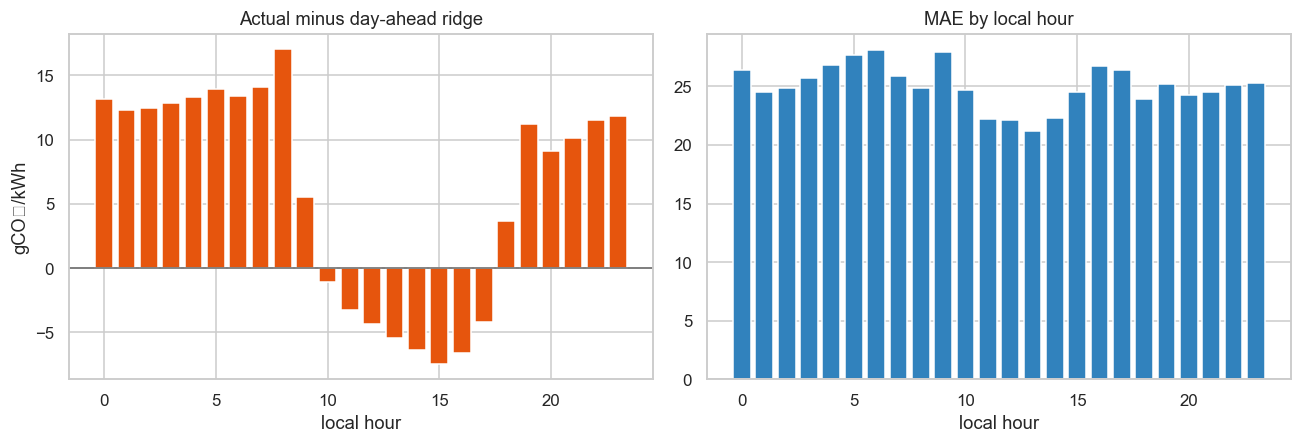

/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


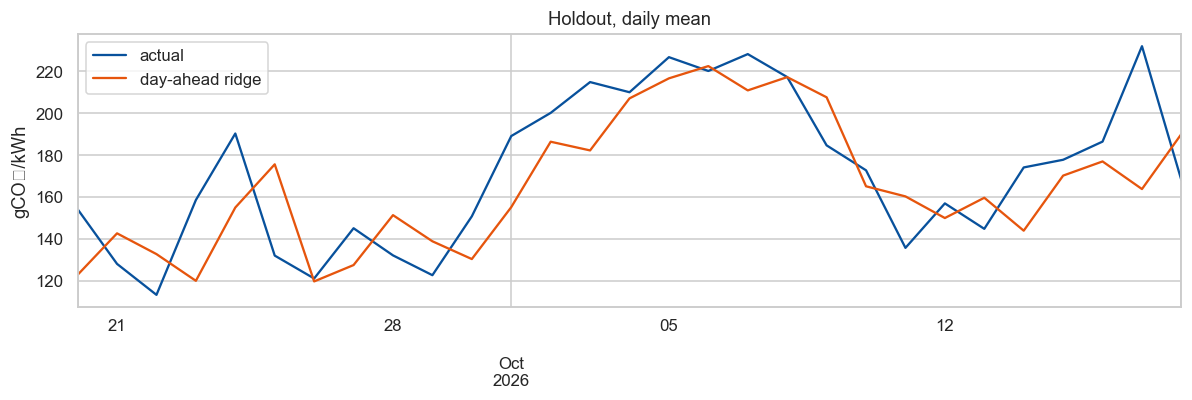

In [3]:
scored = pd.DataFrame(
    {
        "hour_local": test["hour_local"].to_numpy(),
        "actual": test[TARGET].to_numpy(),
        "predicted": forecasts["day-ahead ridge"],
    }
)
scored["too_clean"] = scored["actual"] - scored["predicted"]
by_hour = scored.groupby("hour_local").agg(
    bias=("too_clean", "mean"),
    mae=("too_clean", lambda values: values.abs().mean()),
)
worst_hour = int(by_hour["mae"].idxmax())
print(
    f"Largest MAE is local hour {worst_hour}: {by_hour.loc[worst_hour, 'mae']:.1f} g/kWh, "
    f"average residual {by_hour.loc[worst_hour, 'bias']:.1f} "
    f"(positive means the hour was dirtier than the forecast)."
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
axes[0].bar(by_hour.index, by_hour["bias"], color="#e6550d")
axes[0].axhline(0, color="0.4", lw=1)
axes[0].set_title("Actual minus day-ahead ridge")
axes[0].set_ylabel("gCO₂/kWh")
axes[0].set_xlabel("local hour")
axes[1].bar(by_hour.index, by_hour["mae"], color="#3182bd")
axes[1].set_title("MAE by local hour")
axes[1].set_xlabel("local hour")
fig.tight_layout()

daily = pd.DataFrame(
    {"actual": test[TARGET].to_numpy(), "day-ahead ridge": forecasts["day-ahead ridge"]},
    index=test.index.tz_convert("America/Los_Angeles"),
).resample("D").mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
daily.plot(ax=ax, color=["#08519c", "#e6550d"])
ax.set_ylabel("gCO₂/kWh")
ax.set_title("Holdout, daily mean")
ax.set_xlabel("")
fig.tight_layout()
